# Step 8: Model comparison, transfer and research questions

One leaderboard for every model on every evaluation set, written to `results/ensemble/leaderboard_all_models.csv`. Details: `docs/steps/08_model_comparison.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


In [2]:
# Leaderboard on all sets
frames = []
for test_set, _, _ in U.EVAL_SETS:
    t, v = U.predictions(test_set)
    frames.append(U.evaluate(t, v).assign(set=test_set))
    print(test_set, "done")
lb = pd.concat(frames, ignore_index=True)
lb.to_csv(U.RESULTS / "leaderboard_all_models.csv", index=False)
main = lb[lb.set == "sarc_random"]
U.show(main[["label", "family", "compliant", "roc_auc", "precision", "recall", "f1", "p75_recall"]])

sarc_random done


sarc_subreddit done


figlang_reddit done


figlang_twitter done


tweeteval_irony done


news_headlines done


,label,family,compliant,roc_auc,precision,recall,f1,p75_recall
0,"RoBERTa, reply + parent, converged",Pretrained,False,0.8809,0.7880,0.8216,0.8045,0.8640
1,"RoBERTa, converged, 2nd seed",Pretrained,False,0.8808,0.7900,0.8161,0.8029,0.8633
2,"RoBERTa, reply + parent, 1 epoch",Pretrained,False,0.8718,0.7846,0.8007,0.7926,0.8465
3,"RoBERTa, reply only, 1 epoch",Pretrained,False,0.8599,0.7839,0.7744,0.7792,0.8182
4,"LightGBM, all features incl. MiniLM",GBDT,False,0.8330,0.7736,0.7275,0.7498,0.7585
5,LightGBM + LR score + cues + contrast,GBDT,True,0.8296,0.7746,0.7209,0.7468,0.7512
6,LightGBM + MiniLM embeddings,GBDT,False,0.8270,0.7673,0.7246,0.7453,0.7487
7,LightGBM + LR score,GBDT,True,0.8264,0.7723,0.7171,0.7437,0.7466
8,"From-scratch ESIM, reply + parent",Scratch NN,True,0.8242,0.7485,0.7514,0.7499,0.7433
9,Full-data EBM (66 features + text score),Glass-box,True,0.8229,0.7712,0.7131,0.7410,0.7375


## 8.1 Compliant vs reference

In [3]:
# AUC by set
wide = lb.pivot_table(index="model", columns="set", values="roc_auc")
wide = wide[[s for s, _, _ in U.EVAL_SETS]]
wide.insert(0, "compliant", [U.info(m)["compliant"] for m in wide.index]); wide.insert(0, "family", [U.info(m)["family"] for m in wide.index])
U.show(wide.sort_values("sarc_random", ascending=False))

set,family,compliant,sarc_random,sarc_subreddit,figlang_reddit,figlang_twitter,tweeteval_irony,news_headlines
model,,,,,,,,
roberta_pair_conv,Pretrained,False,0.8809,0.8762,0.8276,0.7479,0.6973,0.5057
roberta_pair_conv_s4248,Pretrained,False,0.8808,NaN,0.8321,0.7422,0.7024,0.4976
roberta_pair,Pretrained,False,0.8718,0.8670,0.8246,0.7226,0.6965,0.4689
roberta_reply,Pretrained,False,0.8599,NaN,0.8192,0.6770,0.6822,0.4709
lgbm_combined_best,GBDT,False,0.8330,0.8251,0.7761,0.6310,0.6141,0.4554
lgbm_lrscore_cues_contrast,GBDT,True,0.8296,0.8226,0.7700,0.6225,0.6140,0.4508
lgbm_minilm_v60k_cues_contrast,GBDT,False,0.8270,0.8208,0.7765,0.6361,0.6009,0.4639
lgbm_lrscore,GBDT,True,0.8264,0.8187,0.7728,0.6213,0.6075,0.4486
scratch_pair,Scratch NN,True,0.8242,0.8153,0.7589,0.6377,0.6484,0.4769


## 8.2 Cross-platform transfer (models trained on sarc_random, no target-side fitting)

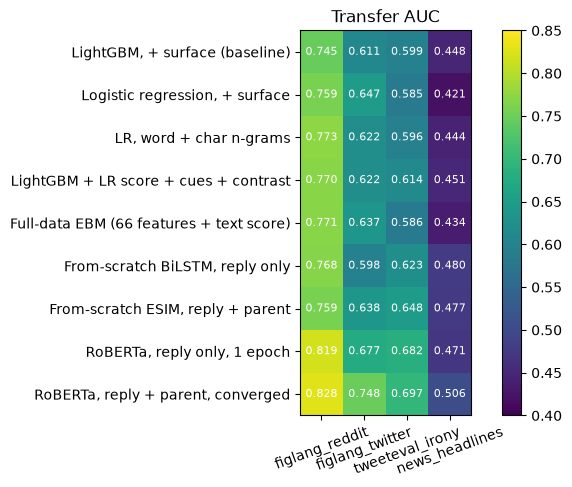

In [4]:
# Transfer heatmap
T = ["lgbm_reply_tfidf_surface", "lr_reply_tfidf_surface", "lr_word_char_surface", "lgbm_lrscore_cues_contrast", "ebm_full",
     "scratch_reply", "scratch_pair", "roberta_reply", "roberta_pair_conv"]
tr = wide.loc[T, ["figlang_reddit", "figlang_twitter", "tweeteval_irony", "news_headlines"]]
tr.index = [U.info(m)["label"] for m in T]
fig, ax = plt.subplots(figsize=(8, 5)); im = ax.imshow(tr.values, cmap="viridis", vmin=0.4, vmax=0.85)
ax.set_xticks(range(tr.shape[1])); ax.set_xticklabels(tr.columns, rotation=20); ax.set_yticks(range(len(tr))); ax.set_yticklabels(tr.index)
for i in range(tr.shape[0]):
    for j in range(tr.shape[1]): ax.text(j, i, f"{tr.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
fig.colorbar(im); ax.set_title("Transfer AUC"); U.savefig(fig, "S08_transfer.png"); plt.show()

## 8.3 Where the gains come from (sarc_random test AUC)

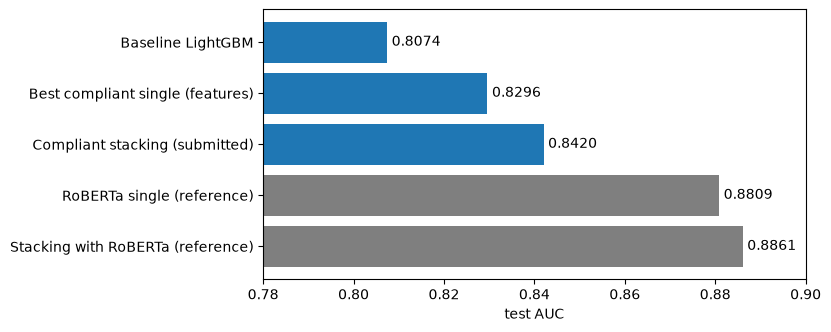

Baseline LightGBM                    0.8074
Best compliant single (features)     0.8296
Compliant stacking (submitted)       0.8420
RoBERTa single (reference)           0.8809
Stacking with RoBERTa (reference)    0.8861
dtype: float64

In [5]:
# Gain ladder
ens = pd.read_csv(U.EXP / "11_full_convergence/results/ensemble_compliant_with_scratch/ensemble_results.csv").set_index(["set", "method"])
ref = pd.read_csv(U.EXP / "11_full_convergence/results/ensemble_final/ensemble_results.csv").set_index(["set", "method"])
a = main.set_index("model")["roc_auc"]
ladder = pd.Series({"Baseline LightGBM": a["lgbm_reply_tfidf_surface"],
                    "Best compliant single (features)": a["lgbm_lrscore_cues_contrast"],
                    "Compliant stacking (submitted)": ens.loc[("sarc_random", "blend_meta_lr"), "test_roc_auc"],
                    "RoBERTa single (reference)": a["roberta_pair_conv"],
                    "Stacking with RoBERTa (reference)": ref.loc[("sarc_random", "blend_meta_lr"), "test_roc_auc"]})
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.barh(ladder.index[::-1], ladder.values[::-1], color=["tab:gray", "tab:gray", "tab:blue", "tab:blue", "tab:blue"])
ax.set_xlim(0.78, 0.9); ax.set_xlabel("test AUC"); [ax.text(v + 0.001, i, f"{v:.4f}", va="center") for i, v in enumerate(ladder.values[::-1])]
U.savefig(fig, "S08_gain_ladder.png"); plt.show(); ladder.round(4)

## 8.4 Research questions

In [6]:
# Context evidence for Q1
test, val = U.predictions("sarc_random")
q1 = pd.concat([U.bootstrap_vs(test, ["lgbm_contrast"], ref="lgbm_reply_tfidf_surface"),
                U.bootstrap_vs(test, ["scratch_pair"], ref="scratch_reply"),
                U.bootstrap_vs(test, ["roberta_pair"], ref="roberta_reply")])
q1["evidence"] = ["hand-made contrast features", "from-scratch ESIM vs BiLSTM", "RoBERTa pair vs reply (reference)"]
U.show(q1[["evidence", "d_auc", "ci_low", "ci_high"]])

,evidence,d_auc,ci_low,ci_high
0,hand-made contrast features,0.0029,0.0023,0.0035
0,from-scratch ESIM vs BiLSTM,0.0063,0.0050,0.0074
0,RoBERTa pair vs reply (reference),0.0119,0.0112,0.0126


| Question | Evidence | Answer |
|---|---|---|
| **Q1** Is the parent comment needed? | contrast features +0.003; from-scratch ESIM +0.006; RoBERTa +0.012; parent bag-of-words ≈ 0; LSA −0.006 | **Yes, context helps**, but only with a model that compares reply and parent token by token; the gain grows with that ability. |
| **Q2** Do linguistic cues help? | explicit cues +0.0045 on both splits; character n-grams +0.011 | Yes, robustly; character-level form cues cover more than hand-written rules. |
| **Q3** Is subreddit needed? | every gain is the same on unseen communities; removing the only subreddit member costs ≈0.0006 | No. |

**Limitations.** One seed for compliant models; 84% of test authors also appear in training (author-disjoint check pending); the "no full stop at the end" signal may be a SARC artefact; VADER (lexicon + rules, not trained) should be confirmed as allowed. The planned ablations A1–A9 are listed in `docs/SUMMARY.md`.